
# Iris Flower Classification

## 1. Introduction

Iris Flower Classification is a Machine Learning classification project that predicts the species of an Iris flower based on its physical measurements.

The project uses the built-in Iris dataset provided by Scikit-learn.

## 2. Objective

The main objective is to classify Iris flowers into three species:

- Iris Setosa
- Iris Versicolor
- Iris Virginica

## 3. Dataset Description

The dataset contains 150 observations and four input features:

1. Sepal Length
2. Sepal Width
3. Petal Length
4. Petal Width

The target variable represents the flower species.

## 4. Machine Learning Algorithms

We will train and compare:

- Logistic Regression
- K-Nearest Neighbors (KNN)

## 5. Evaluation Metrics

- Accuracy Score
- Confusion Matrix
- Classification Report


In [1]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Set visualization style
sns.set_style("whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# Load the built-in Iris dataset

iris = load_iris()

# Convert dataset into a DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add target column
df["species"] = iris.target

# Convert numerical target values into flower names
df["species"] = df["species"].map({
    0: "Setosa",
    1: "Versicolor",
    2: "Virginica"
})

# Display first five rows
df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


In [3]:

# Display dataset dimensions
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns)

# Display dataset information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Display statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Count each flower species
print("\nSpecies Distribution:")
print(df["species"].value_counts())


Dataset Shape: (150, 5)

Column Names:
Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'species'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Statistical Summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Species Distribution:
species
Setosa        50
Versicolor    50
Virginica     50
Name: count, dtype: int64


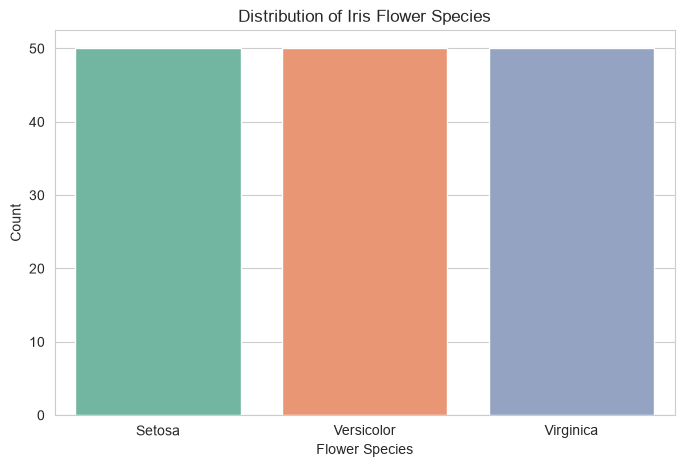

In [4]:

# Count the number of flowers in each species

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="species",
    hue="species",
    palette="Set2",
    legend=False
)

plt.title("Distribution of Iris Flower Species")
plt.xlabel("Flower Species")
plt.ylabel("Count")
plt.show()


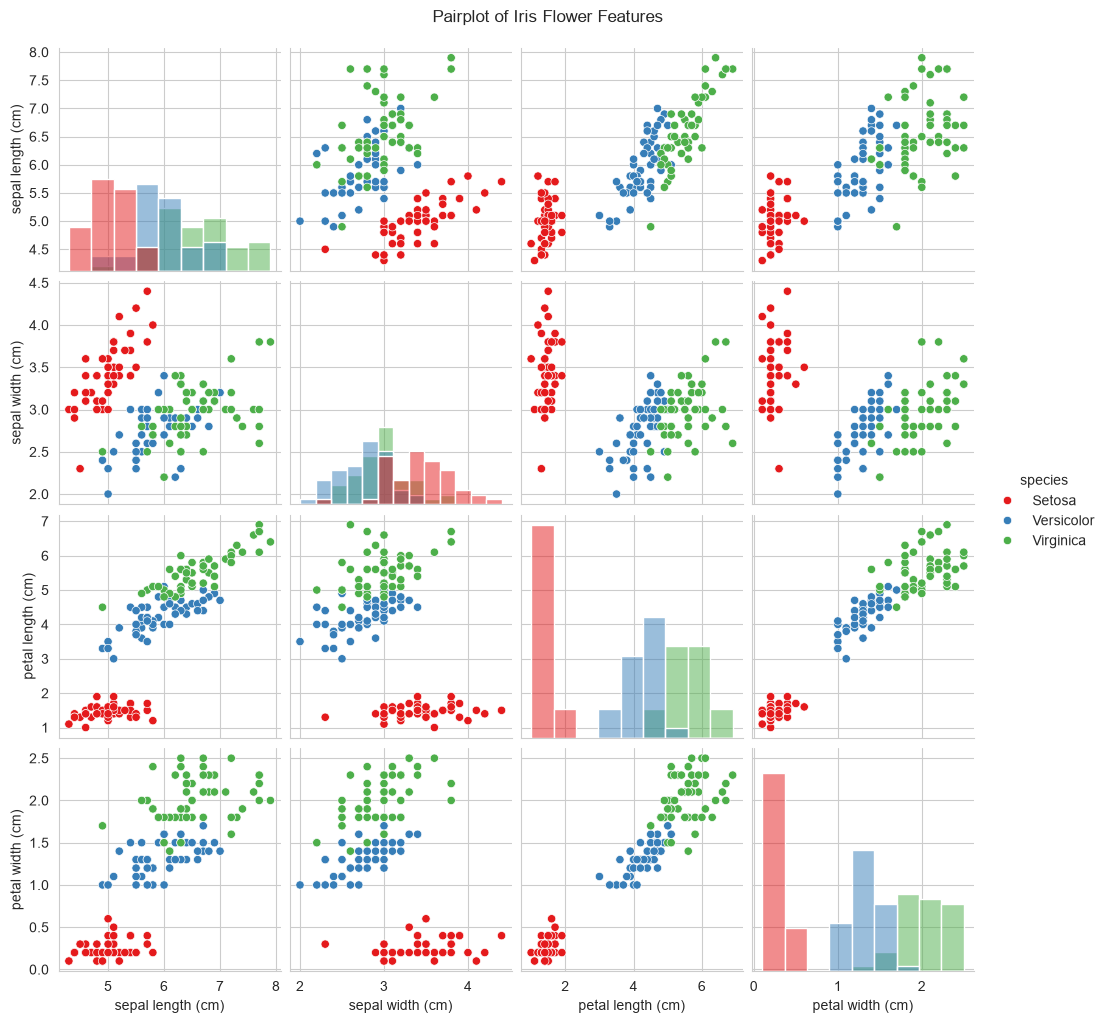

In [5]:

# Pairplot of Iris dataset

sns.pairplot(
    df,
    hue="species",
    palette="Set1",
    diag_kind="hist"
)

plt.suptitle(
    "Pairplot of Iris Flower Features",
    y=1.02
)

plt.show()


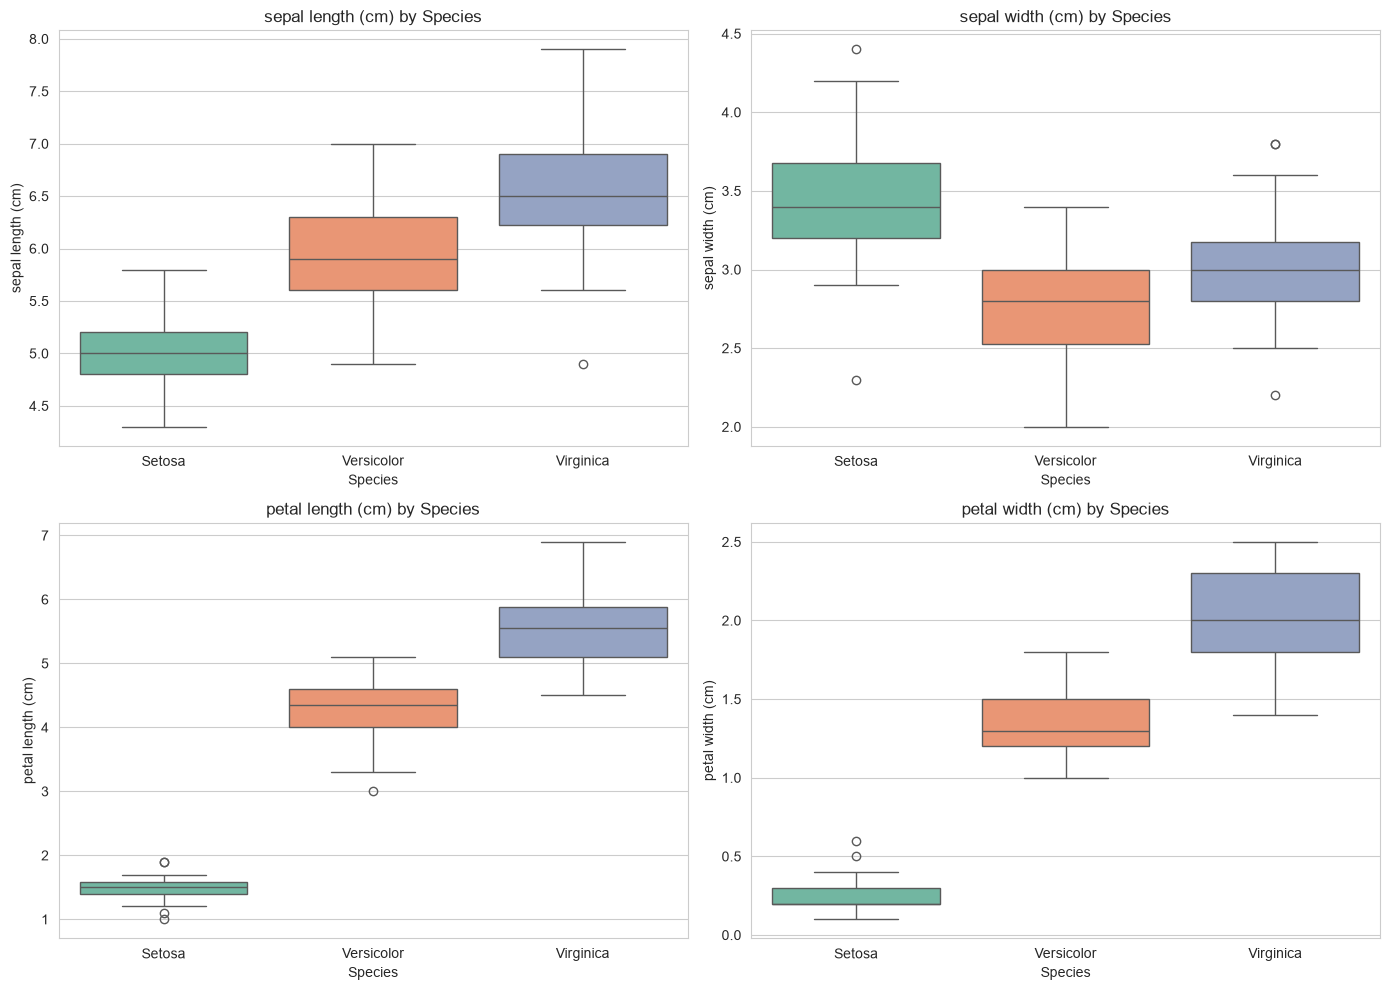

In [6]:

# Select numerical features
features = iris.feature_names

# Create boxplots
plt.figure(figsize=(14, 10))

for i, feature in enumerate(features, 1):
    plt.subplot(2, 2, i)

    sns.boxplot(
        data=df,
        x="species",
        y=feature,
        hue="species",
        palette="Set2",
        legend=False
    )

    plt.title(f"{feature} by Species")
    plt.xlabel("Species")
    plt.ylabel(feature)

plt.tight_layout()
plt.show()



## Feature Selection

The Iris dataset contains four numerical features: sepal length, sepal width, petal length, and petal width.

Based on the pairplot and boxplot visualizations, petal length and petal width show better separation among the three flower species.

Sepal measurements also provide useful information, although some overlap exists between species.

Therefore, all four features are selected for model training to retain the available information and improve classification performance.


In [7]:

# Separate input features and target variable

X = df.drop("species", axis=1)
y = df["species"]

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training data shape: (120, 4)
Testing data shape: (30, 4)
Training samples: 120
Testing samples: 30


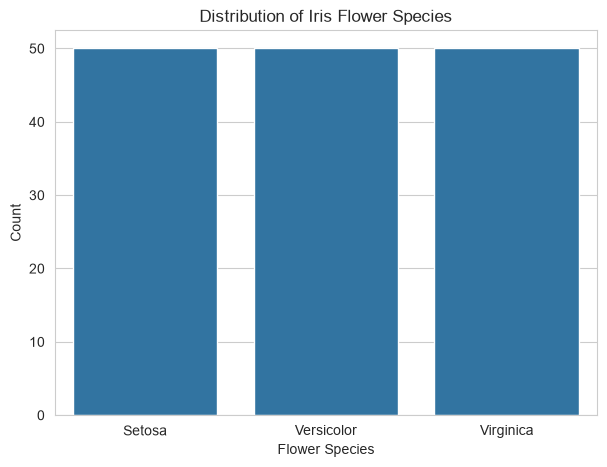

In [8]:

# Count the number of flowers in each species
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="species")

plt.title("Distribution of Iris Flower Species")
plt.xlabel("Flower Species")
plt.ylabel("Count")
plt.show()


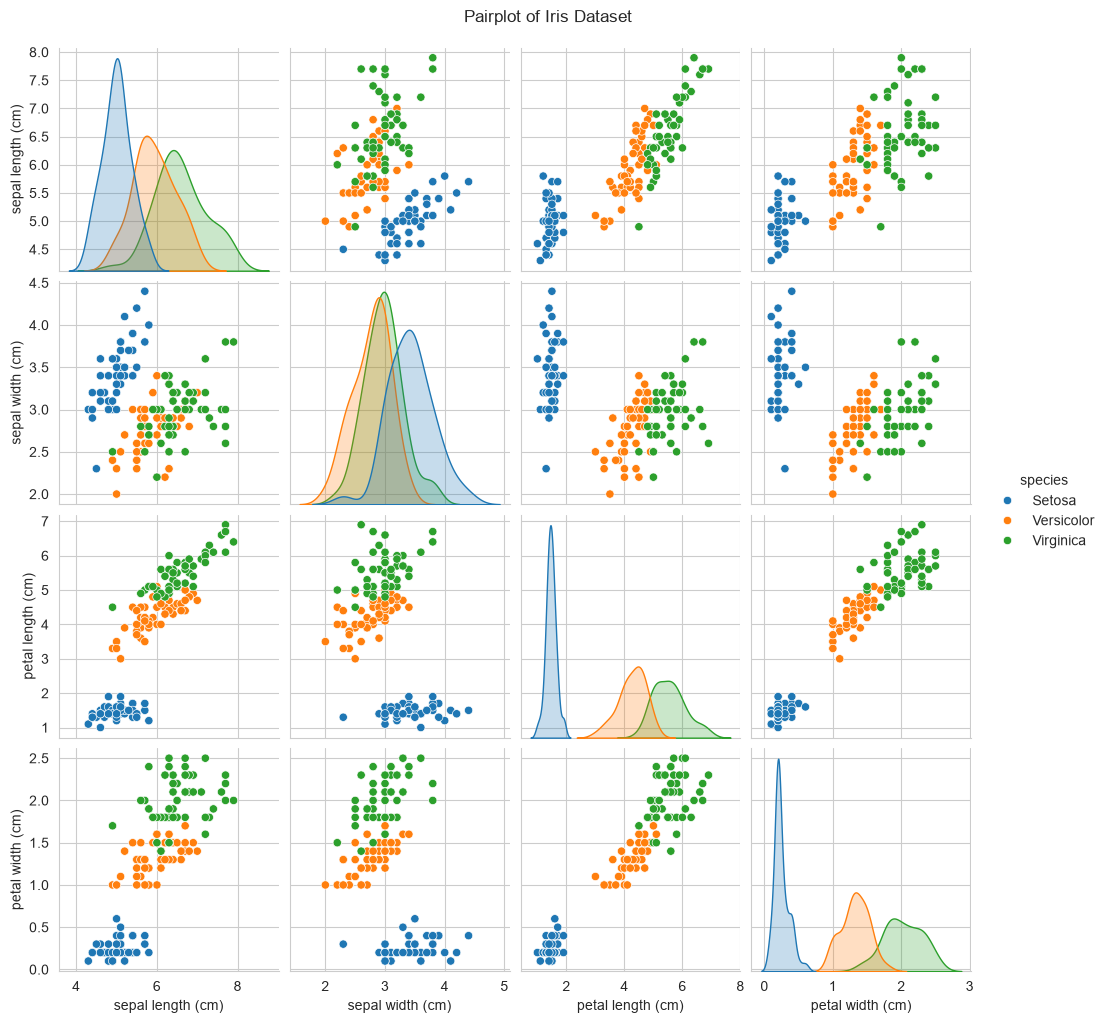

In [9]:

# Pairplot to visualize relationships between features
sns.pairplot(
    df,
    hue="species",
    height=2.5
)

plt.suptitle(
    "Pairplot of Iris Dataset",
    y=1.02
)

plt.show()



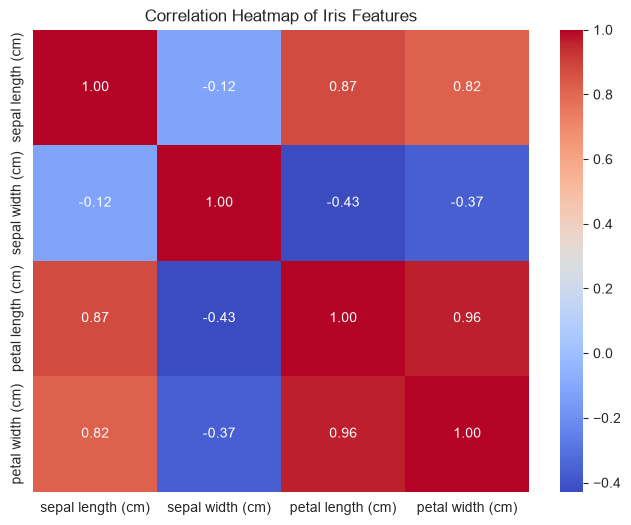

In [10]:

# Correlation heatmap

plt.figure(figsize=(8, 6))

correlation = df[iris.feature_names].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Iris Features")
plt.show()



## Feature Selection

The Iris dataset contains four numerical features.

Based on the pairplot and correlation heatmap, petal length and petal width show strong relationships with flower species.

All four features are retained for model training to preserve the available information and compare classification performance.


In [11]:

# Separate input features and target variable

X = df.drop("species", axis=1)
y = df["species"]

# Split dataset into 80% training and 20% testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset sizes

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (120, 4)
Testing Features: (30, 4)
Training Target: (120,)
Testing Target: (30,)


In [12]:

# Create Logistic Regression pipeline

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train model
logistic_model.fit(X_train, y_train)

# Make predictions
logistic_predictions = logistic_model.predict(X_test)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [13]:

# Create KNN pipeline

knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

# Train model
knn_model.fit(X_train, y_train)

# Make predictions
knn_predictions = knn_model.predict(X_test)

print("KNN model trained successfully!")



KNN model trained successfully!


In [14]:

# Calculate model accuracy

logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)

knn_accuracy = accuracy_score(
    y_test,
    knn_predictions
)

print("Logistic Regression Accuracy:",
      round(logistic_accuracy * 100, 2), "%")

print("KNN Accuracy:",
      round(knn_accuracy * 100, 2), "%")



Logistic Regression Accuracy: 93.33 %
KNN Accuracy: 93.33 %


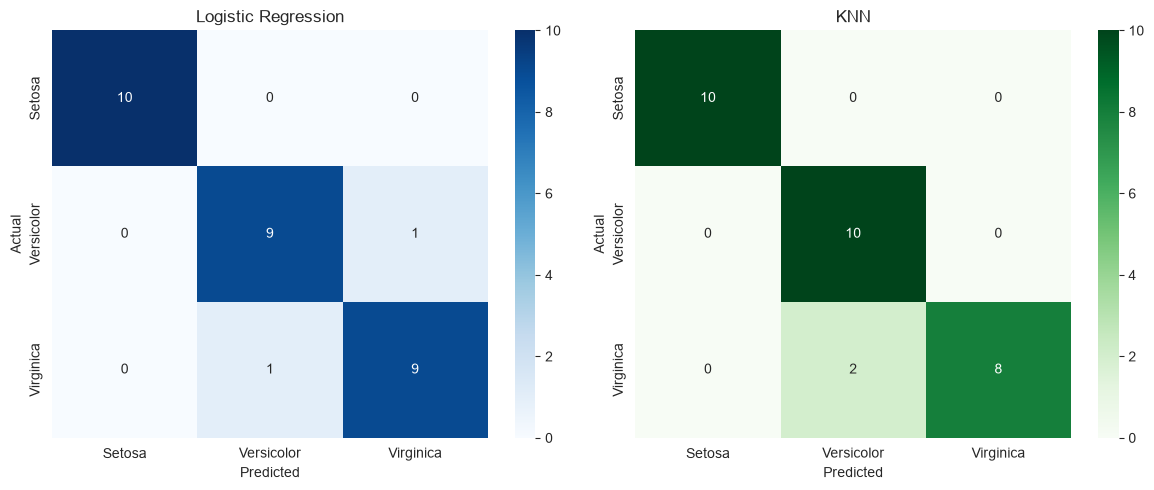

In [15]:

# Logistic Regression Confusion Matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    confusion_matrix(
        y_test,
        logistic_predictions,
        labels=["Setosa", "Versicolor", "Virginica"]
    ),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Setosa", "Versicolor", "Virginica"],
    yticklabels=["Setosa", "Versicolor", "Virginica"],
    ax=axes[0]
)

axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# KNN Confusion Matrix

sns.heatmap(
    confusion_matrix(
        y_test,
        knn_predictions,
        labels=["Setosa", "Versicolor", "Virginica"]
    ),
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Setosa", "Versicolor", "Virginica"],
    yticklabels=["Setosa", "Versicolor", "Virginica"],
    ax=axes[1]
)

axes[1].set_title("KNN")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()


In [16]:

print("LOGISTIC REGRESSION CLASSIFICATION REPORT")
print(classification_report(y_test, logistic_predictions))

print("\nKNN CLASSIFICATION REPORT")
print(classification_report(y_test, knn_predictions))


LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       0.90      0.90      0.90        10
   Virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


KNN CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       0.83      1.00      0.91        10
   Virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



In [17]:

# Compare model accuracy

results = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN"],
    "Accuracy": [logistic_accuracy, knn_accuracy]
})

print(results)

# Select best model
if logistic_accuracy >= knn_accuracy:
    best_model = logistic_model
    best_model_name = "Logistic Regression"
else:
    best_model = knn_model
    best_model_name = "KNN"

print("\nBest Performing Model:", best_model_name)


                 Model  Accuracy
0  Logistic Regression  0.933333
1                  KNN  0.933333

Best Performing Model: Logistic Regression


In [18]:

# New flower measurements:
# Sepal length = 5.1
# Sepal width = 3.5
# Petal length = 1.4
# Petal width = 0.2

new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

prediction = best_model.predict(new_flower)

print("Predicted Flower Species:", prediction[0])


Predicted Flower Species: Setosa



# 13. Conclusion

In this project, we successfully developed a machine learning model to classify Iris flowers into Setosa, Versicolor, and Virginica species.

The Iris dataset was explored using statistical analysis and data visualization techniques.

Two classification algorithms, Logistic Regression and K-Nearest Neighbors (KNN), were implemented and evaluated.

The models were compared using accuracy, confusion matrices, precision, recall, and F1-score.

The best-performing model was selected based on test accuracy.

The final model was also tested using new flower measurements and successfully predicted the flower species.

## Future Improvements

- Experiment with Decision Tree and Random Forest classifiers.
- Perform hyperparameter tuning.
- Apply cross-validation for more reliable evaluation.
- Develop a simple web application for flower prediction.


In [19]:

# Final model comparison

final_results = pd.DataFrame({
    "Model": ["Logistic Regression", "K-Nearest Neighbors"],
    "Accuracy (%)": [
        logistic_accuracy * 100,
        knn_accuracy * 100
    ]
})

final_results["Accuracy (%)"] = final_results["Accuracy (%)"].round(2)

display(final_results)

print("Best Model:", best_model_name)
print("Best Accuracy:", round(max(logistic_accuracy, knn_accuracy) * 100, 2), "%")


,Model,Accuracy (%)
0,Logistic Regression,93.33
1,K-Nearest Neighbors,93.33


Best Model: Logistic Regression
Best Accuracy: 93.33 %
